# Lending Club Loan Default Prediction

## 1. Business Background and Prediction Objective

An investment company plans to invest **$10 million** in Lending Club loans
and needs to identify loans at higher risk of default.

According to the assignment description, the dataset contains **7,151 loans
and 16 variables**, covering **36-month loans issued in 2015 for credit card
financing**.

- **Target variable:** `loan_status`, encoded as **1 = Charged Off**
  and **0 = Fully Paid**.
- **Predictor variables:** Borrower and loan characteristics available
  at the time of investment.
- **Modeling objective:** Develop and compare **Logistic Regression**
  and **Decision Tree Classification** models to support loan selection.
- **Evaluation focus:** Prioritize recall for charged-off loans while
  considering precision and ROC AUC.

The analysis will emphasize feature-selection decisions, data preparation,
model interpretation, and validation rather than extensive optimization.

## 2. Data Loading and Initial Preparation
### 2.1 Load the Dataset

Load the Excel file and check the number of rows, columns, and first five records.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Prefer the assignment file; otherwise use the existing local dataset cache.
DATA_PATH = Path("loan_data.xlsx")
if not DATA_PATH.is_file():
    DATA_PATH = Path(".kagglehub/datasets/jayantmathur/lending-club-dataset/versions/1/"
                     "_333d0aff25cda9e5baa453d609e525eb_data-capstone-project.xlsx")
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place loan_data.xlsx beside this notebook or set DATA_PATH to its full path.")

raw = pd.read_excel(DATA_PATH)
df = raw.copy()
print(f"Data source: {DATA_PATH.resolve()}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print("Column names:", df.columns.tolist())
display(df.head())

Data source: /Users/zhaofengyi/Documents/New project/.kagglehub/datasets/jayantmathur/lending-club-dataset/versions/1/_333d0aff25cda9e5baa453d609e525eb_data-capstone-project.xlsx
Number of rows: 7,151
Number of columns: 16
Column names: ['id', 'member_id', 'term', 'purpose', 'loan_status', 'loan_amnt', 'int_rate', 'installment', 'home_ownership', 'annual_inc', 'verification_status', 'revol_bal', 'revol_util', 'total_acc', 'acc_open_past_24mths', 'total_pymnt']


/opt/anaconda3/lib/python3.13/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


,id,member_id,term,purpose,loan_status,loan_amnt,int_rate,installment,home_ownership,annual_inc,verification_status,revol_bal,revol_util,total_acc,acc_open_past_24mths,total_pymnt
0,62286683,66483442,36 months,credit_card,Fully Paid,24000,7.89,750.86,MORTGAGE,237500.0,Source Verified,28279,36.9,25,5,24948.450004
1,46314315,49422035,36 months,credit_card,Fully Paid,8000,6.68,245.85,RENT,41000.0,Not Verified,24377,51.0,29,2,8351.630000
2,51317198,54726945,36 months,credit_card,Fully Paid,12175,9.17,388.13,MORTGAGE,100000.0,Not Verified,21329,64.6,17,3,13205.910000
3,42984750,45981489,36 months,credit_card,Charged Off,6400,6.92,197.38,RENT,41900.0,Source Verified,14936,73.2,15,1,3550.380000
4,42181434,45138158,36 months,credit_card,Fully Paid,12600,6.68,387.22,OWN,73800.0,Not Verified,9904,20.7,25,4,13125.770000


### 2.2 Check Data Quality and Target Distribution

Before preparing features, inspect:

- **Data types:** Confirm that numerical and categorical variables are stored appropriately.
- **Missing values:** Identify columns that may require imputation or further investigation.
- **Duplicate records:** Check for repeated rows that could affect the analysis.
- **Target distribution:** Confirm the values in `loan_status` and assess class imbalance.

These checks will guide our cleaning decisions. No rows or columns are
removed at this stage.

In [2]:
# Summarize data types, missing values, and distinct values
data_summary = pd.DataFrame({
    "data_type": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "unique_count": df.nunique()
})

display(data_summary)

# Check for exact duplicate rows
print(f"Duplicate rows: {df.duplicated().sum():,}")

# Inspect the target values, including any missing labels
target_summary = (
    df["loan_status"]
    .value_counts(dropna=False)
    .rename_axis("loan_status")
    .to_frame("count")
)

target_summary["percentage"] = (
    target_summary["count"].div(len(df)).mul(100).round(2)
)

display(target_summary)

,data_type,missing_count,missing_pct,unique_count
id,int64,0,0.00,7151
member_id,int64,0,0.00,7151
term,object,0,0.00,1
purpose,object,0,0.00,1
loan_status,object,0,0.00,2
loan_amnt,int64,0,0.00,680
int_rate,float64,0,0.00,85
installment,float64,0,0.00,2864
home_ownership,object,0,0.00,3
annual_inc,float64,0,0.00,1085


Duplicate rows: 0


,count,percentage
loan_status,,
Fully Paid,5943,83.11
Charged Off,1208,16.89


#### Target Distribution and Class Imbalance

Fully Paid loans account for **83.11%** of the dataset, while Charged Off loans account for **16.89%**, indicating class imbalance.

A model that predicts every loan as Fully Paid would achieve 83.11% accuracy but identify none of the charged-off loans. Therefore, accuracy alone would be misleading.

We will address this by:

- Using stratified train, validation and test splits to preserve the class proportions.
- Setting `class_weight="balanced"` in both models to give charged-off loans greater weight during training.
- Prioritizing recall to reduce missed defaults, while checking precision to understand how many flagged loans actually charge off.
- Using ROC AUC to evaluate how well the models rank charged-off loans above fully paid loans across thresholds.

### 2.3 Define the Target and Exclude Unsuitable Features

The target variable is `loan_status`, encoded as **1 = Charged Off**
and **0 = Fully Paid**.

Based on the initial checks, exclude the following features:

| Features | Finding and reason for exclusion |
|---|---|
| `id`, `member_id` | Each has 7,151 unique values and serves as a record or borrower identifier. Their numerical values do not describe repayment ability. Including them could introduce arbitrary patterns that do not generalize to new loans. |
| `term`, `purpose` | Each contains only one unique value because the dataset is restricted to 36-month loans for credit card financing. With no variation across loans, these features cannot help distinguish Fully Paid from Charged Off outcomes within this dataset. |
| `total_pymnt` | Represents payments received after loan issuance. It would not be available when selecting investments, so including it would introduce data leakage and overstate predictive performance. |

Retain the remaining 10 predictors for further exploration.

In [3]:
# Fail explicitly instead of silently converting unsupported labels to NaN.
valid_labels = {"Charged Off", "Fully Paid"}
if not df["loan_status"].isin(valid_labels).all():
    raise ValueError("loan_status must contain only Charged Off or Fully Paid, with no missing labels.")
if df["id"].isna().any() or df["id"].duplicated().any():
    raise ValueError("Loan IDs must be present and unique before splitting.")

# Encode the target: 1 = Charged Off, 0 = Fully Paid
y = df["loan_status"].map({"Charged Off": 1, "Fully Paid": 0})

# Remove the target and unsuitable predictors
excluded_columns = [
    "loan_status", "id", "member_id", "term", "purpose", "total_pymnt"]
X = df.drop(columns=excluded_columns)

print(f"Number of predictors: {X.shape[1]}")
print("Predictors:", X.columns.tolist())

Number of predictors: 10
Predictors: ['loan_amnt', 'int_rate', 'installment', 'home_ownership', 'annual_inc', 'verification_status', 'revol_bal', 'revol_util', 'total_acc', 'acc_open_past_24mths']


### 2.4 Split Training, Validation, and Test Data

Split the data into three sets:

- **Training (60%):** Explore feature relationships, fit preprocessing steps,
  and train the models.
- **Validation (20%):** Compare models and select any model settings or
  classification thresholds.
- **Test (20%):** Evaluate the final selected model once decisions are complete.

Use stratified sampling to preserve approximately the same proportion of
Charged Off loans in each set. This matters because only 16.89% of loans
belong to this class.

Set a fixed random seed so the split is reproducible. Both models will use
the same split for a fair comparison.

In [4]:
from sklearn.model_selection import train_test_split

# Reserve 20% for final testing
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Split the remaining 80% into 60% training and 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

# Check sample sizes and target proportions
split_summary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],
    "loan_count": [len(y_train), len(y_val), len(y_test)],
    "charged_off_pct": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(2))

,dataset,loan_count,charged_off_pct
0,Training,4290,16.90
1,Validation,1430,16.85
2,Test,1431,16.91


## 3. Exploratory Data Analysis — Training Set
### 3.1 Numerical Feature Distributions

Review summary statistics and distributions in the training set to identify:

- **Skewness:** Compare the mean and median and inspect long tails.
- **Extreme values:** Investigate unusually large or small observations.
- **Different scales:** Assess the need for scaling before Logistic Regression.

These findings will guide preprocessing. Extreme values are not automatically
errors, and Logistic Regression does not require normally distributed features.

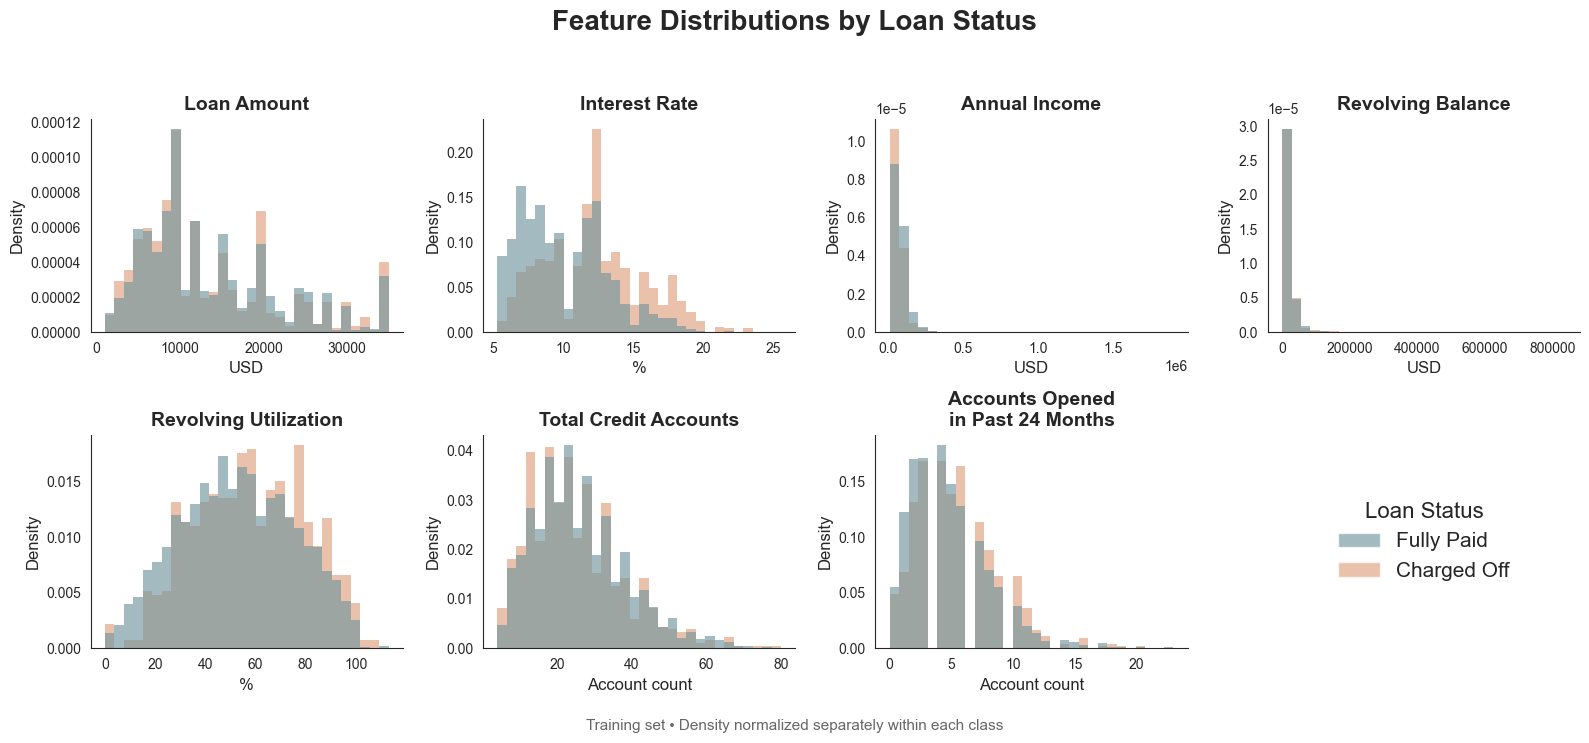

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

plot_data = X_train.assign(
    loan_status=y_train.map({0: "Fully Paid", 1: "Charged Off"})
)

features = [
    ("loan_amnt", "Loan Amount", "USD"),
    ("int_rate", "Interest Rate", "%"),
    ("annual_inc", "Annual Income", "USD"),
    ("revol_bal", "Revolving Balance", "USD"),
    ("revol_util", "Revolving Utilization", "%"),
    ("total_acc", "Total Credit Accounts", "Account count"),
    ("acc_open_past_24mths", "Accounts Opened\nin Past 24 Months", "Account count"),
]

colors = ["#72979F", "#DFA17D"]
labels = ["Fully Paid", "Charged Off"]

with sns.axes_style("white"):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))

    for ax, (col, title, unit) in zip(axes.flat, features):
        sns.histplot(
            data=plot_data, x=col, hue="loan_status",
            hue_order=labels, palette=colors,
            bins=30, stat="density",
            common_norm=False, common_bins=True,
            alpha=0.65, linewidth=0,
            legend=False, ax=ax,
        )
        ax.set_title(title, fontsize=14, fontweight="bold")
        ax.set_xlabel(unit, fontsize=12)
        ax.set_ylabel("Density", fontsize=12)
        ax.tick_params(labelsize=10)
        sns.despine(ax=ax)

    # Use the last panel for a shared legend.
    axes[1, 3].axis("off")
    axes[1, 3].legend(
        handles=[
            Patch(facecolor=color, alpha=0.65, label=label)
            for color, label in zip(colors, labels)
        ],
        loc="center", frameon=False, fontsize=15,
        title="Loan Status", title_fontsize=16,
    )

    fig.suptitle(
        "Feature Distributions by Loan Status",
        fontsize=20, fontweight="bold",
    )
    fig.text(
        0.5, 0.02,
        "Training set • Density normalized separately within each class",
        ha="center", fontsize=11, color="#666666",
    )
    fig.tight_layout(rect=[0, 0.05, 1, 0.94])

    # Export a high-resolution image for PowerPoint.
    fig.savefig("numerical_features_ppt.png", dpi=300, facecolor="white")
    plt.show()

### Numerical Feature Insights

| Features | Observation | Implication |
|---|---|---|
| `annual_inc`, `revol_bal` | Strong right skew with a few very large values. | Inspect the extreme values and consider a log transformation to compress their range. |
| `loan_amnt` | Concentrated at lower values, with a tail toward larger amounts. | Check overlap with `installment` during correlation analysis. |
| `int_rate` | Most observations fall between approximately 5% and 15%, with fewer higher-rate loans. | Examine its relationship with loan outcomes before drawing conclusions about risk. |
| `revol_util` | Values are more evenly spread, with a broad concentration around 40–70. | No strong visual reason for a log transformation. |
| `total_acc`, `acc_open_past_24mths` | Right-skewed counts, with relatively few borrowers having many accounts. | Retain these features and investigate their relationship with loan outcomes. |

The numerical features also have substantially different scales. We will
standardize numerical inputs for Logistic Regression; Decision Tree does
not require scaling.

These plots describe feature distributions, not their predictive importance.
Extreme values will not be removed solely because they are large.

In [6]:
# Inspect the median, upper percentiles, and extremes
skewed_features = ["annual_inc", "revol_bal"]

tail_summary = (
    X_train[skewed_features]
    .describe(percentiles=[0.50, 0.95, 0.99])
    .loc[["min", "50%", "95%", "99%", "max"]]
    .T
)

display(tail_summary.round(2))

,min,50%,95%,99%,max
annual_inc,8000.0,65000.0,160000.00,250000.00,1900000.0
revol_bal,0.0,12786.5,48876.65,99052.87,838698.0


### Extreme Value Assessment

Annual income and revolving balance have long right tails. Their maximum
values are substantially higher than their 99th percentiles.

Retain these observations because there is insufficient evidence that they
are data errors. For Logistic Regression, consider a `log1p` transformation
to compress these ranges, followed by scaling. `log1p` also accommodates
the zero values in revolving balance.

Decision Tree can use the original values. Any benefit from preprocessing
will be assessed on the validation set.

### 3.3 Categorical Features and Charge-Off Rates

Compare loan counts and charge-off rates across home ownership and income
verification categories.

Report group sizes alongside rates because rates based on small groups
may be less reliable. Differences show associations, not causal effects.

In [7]:
# Combine training predictors and labels for exploratory analysis
train_data = X_train.assign(charged_off=y_train)

# Compare group sizes and charge-off rates
for column in ["home_ownership", "verification_status"]:
    category_summary = (
        train_data.groupby(column)["charged_off"]
        .agg(loan_count="size", charged_off_pct="mean")
    )

    category_summary["charged_off_pct"] *= 100

    print(f"\nCharge-off rate by {column}")
    display(category_summary.round(2))


Charge-off rate by home_ownership


,loan_count,charged_off_pct
home_ownership,,
MORTGAGE,1957,12.77
OWN,517,15.86
RENT,1816,21.64



Charge-off rate by verification_status


,loan_count,charged_off_pct
verification_status,,
Not Verified,1393,13.42
Source Verified,1784,15.92
Verified,1113,22.82


### Categorical Feature Insights

Renters have a higher charge-off rate (21.64%) than borrowers with mortgages
(12.77%). This suggests that home ownership may provide useful information
for predicting loan outcomes.

Verified loans have a higher charge-off rate (22.82%) than loans marked
Not Verified (13.42%). This may reflect differences in the borrowers selected
for verification, rather than an effect of verification itself.

Retain both features and use one-hot encoding during preprocessing.
These are unadjusted associations; their additional predictive value will
be assessed alongside the other features.

### 3.4 Correlation Analysis

We examine correlations among numerical predictors and with the target variable using training data.

**Multicollinearity:** Strong relationships among predictors can make Logistic Regression coefficients unstable and difficult to interpret. We pay particular attention to `loan_amnt` and `installment`, because monthly payments depend on the loan amount, interest rate and term. Pairwise correlations help identify potential redundancy but do not detect every form of multicollinearity.

**Association with the target:** Correlations with `loan_status` describe individual associations with charge-off, where Charged Off = 1. Positive values indicate that charged-off loans tend to have higher feature values; negative values indicate lower values.

We combine these findings with business meaning when selecting features. High predictor correlation does not automatically require removal, and weak target correlation does not rule out nonlinear predictive value.

In [8]:
# Define this here so Restart Kernel and Run All works.
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()

# Calculate correlations between numerical predictors
correlation_matrix = X_train[numeric_columns].corr()

# Display a color-coded correlation table
display(
    correlation_matrix.style
    .background_gradient(cmap="coolwarm", vmin=-1, vmax=1)
    .format("{:.2f}")
)

,loan_amnt,int_rate,installment,annual_inc,revol_bal,revol_util,total_acc,acc_open_past_24mths
loan_amnt,1.00,-0.03,1.00,0.47,0.38,0.18,0.19,-0.02
int_rate,-0.03,1.00,0.05,-0.17,-0.05,0.24,-0.11,0.24
installment,1.00,0.05,1.00,0.45,0.38,0.20,0.18,0.00
annual_inc,0.47,-0.17,0.45,1.00,0.39,0.09,0.20,0.03
revol_bal,0.38,-0.05,0.38,0.39,1.00,0.20,0.16,-0.02
revol_util,0.18,0.24,0.20,0.09,0.20,1.00,-0.14,-0.27
total_acc,0.19,-0.11,0.18,0.20,0.16,-0.14,1.00,0.43
acc_open_past_24mths,-0.02,0.24,0.00,0.03,-0.02,-0.27,0.43,1.00


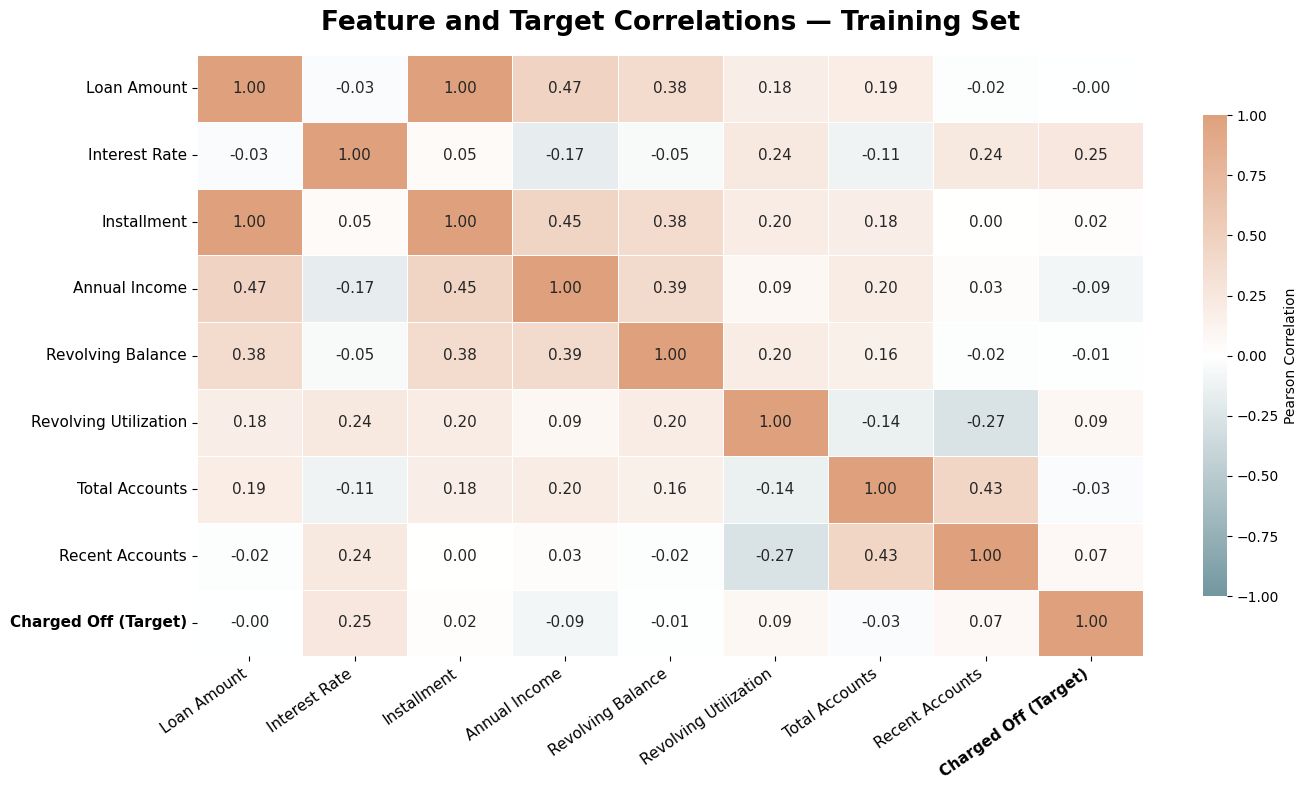

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Include the target for analysis only.
correlation_matrix = (
    X_train.select_dtypes(include="number")
    .assign(loan_status=y_train)
    .corr()
)

labels = {
    "loan_amnt": "Loan Amount",
    "int_rate": "Interest Rate",
    "installment": "Installment",
    "annual_inc": "Annual Income",
    "revol_bal": "Revolving Balance",
    "revol_util": "Revolving Utilization",
    "total_acc": "Total Accounts",
    "acc_open_past_24mths": "Recent Accounts",
    "loan_to_income": "Loan / Income",
    "revol_bal_to_income": "Revolving / Income",
    "loan_status": "Charged Off (Target)",
}

# Match the palette used in the distribution charts.
cmap = LinearSegmentedColormap.from_list(
    "blue_orange", ["#72979F", "#FFFFFF", "#DFA17D"]
)

fig, ax = plt.subplots(figsize=(14, 8))

sns.heatmap(
    correlation_matrix.rename(index=labels, columns=labels),
    annot=True, fmt=".2f", annot_kws={"size": 11},
    cmap=cmap, vmin=-1, vmax=1, center=0,
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Pearson Correlation", "shrink": 0.8},
    ax=ax,
)

ax.set_title(
    "Feature and Target Correlations — Training Set",
    fontsize=19, fontweight="bold", pad=18,
)
ax.set_xticklabels(
    ax.get_xticklabels(), rotation=35, ha="right", fontsize=11
)
ax.set_yticklabels(
    ax.get_yticklabels(), rotation=0, fontsize=11
)

# Highlight the target row and column labels.
ax.get_xticklabels()[-1].set_fontweight("bold")
ax.get_yticklabels()[-1].set_fontweight("bold")

fig.tight_layout()
fig.savefig("correlation_heatmap_ppt.png", dpi=300, facecolor="white")
plt.show()

### Correlation Findings and Feature Selection

`loan_amnt` and `installment` are almost perfectly correlated, with a
correlation that rounds to 1.00. Since all loans have the same 36-month
term, monthly payments largely reflect the loan amount and interest rate.

Drop `installment` and retain `loan_amnt` and `int_rate` to reduce
redundancy and improve the interpretability of Logistic Regression
coefficients.

Use the same nine predictors for both models to keep the comparison
straightforward. Removing `installment` is a simplification, not a
requirement for Decision Tree or a guarantee of better performance.

No other numerical pair shows similarly strong correlation, so retain
the remaining features.

In [10]:
# Apply the feature-selection decision consistently across all sets
selected_features = X.columns.drop("installment")

X_train = X_train[selected_features].copy()
X_val = X_val[selected_features].copy()
X_test = X_test[selected_features].copy()

# Update feature groups for preprocessing
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print(f"Retained predictors: {X_train.shape[1]}")
print("Numerical predictors:", numeric_columns)
print("Categorical predictors:", categorical_columns)

Retained predictors: 9
Numerical predictors: ['loan_amnt', 'int_rate', 'annual_inc', 'revol_bal', 'revol_util', 'total_acc', 'acc_open_past_24mths']
Categorical predictors: ['home_ownership', 'verification_status']


### 3.5 Feature Summary and Modeling Decisions

Based on the EDA, we retain **9 predictors: 7 numerical and 2 categorical features**. The target variable is `loan_status`, where Charged Off = 1 and Fully Paid = 0.

| Feature | Decision | Reason and planned treatment |
|---|---|---|
| `id`, `member_id` | Drop | Identifiers do not describe the borrower's repayment ability. |
| `term`, `purpose` | Drop | Each has only one value in this dataset, so neither helps distinguish loan outcomes within this cohort. |
| `total_pymnt` | Drop | Payments received after loan origination would introduce target leakage. |
| `installment` | Drop | Nearly perfectly correlated with `loan_amnt`. Keeping loan amount and interest rate reduces redundant information. |
| `loan_amnt` | Keep | Represents the amount borrowed and the size of the repayment obligation. |
| `int_rate` | Keep | Loan pricing may reflect the lender's assessment of borrower risk. |
| `annual_inc` | Keep | Provides information about repayment capacity. Apply a log transformation for Logistic Regression to reduce strong right skew. |
| `revol_bal` | Keep | Measures outstanding revolving credit balances. Apply a log transformation for Logistic Regression to reduce strong right skew. |
| `revol_util` | Keep | Measures revolving credit usage relative to available credit. Fill its three missing values with the training-set median. |
| `total_acc` | Keep | Describes the number of credit accounts in the borrower's credit history. |
| `acc_open_past_24mths` | Keep | Captures recent credit account openings and borrowing activity. |
| `home_ownership` | Keep | Training charge-off rates differ across groups: 21.64% for renters versus 12.77% for mortgage holders. Apply one-hot encoding. |
| `verification_status` | Keep | Training charge-off rates differ across groups: 22.82% for Verified versus 13.42% for Not Verified. Apply one-hot encoding. |

These patterns suggest potential predictive value, but they do not establish causation. For example, a higher charge-off rate among verified borrowers does not mean that verification causes default.

Both models will use the same retained predictors. Logistic Regression will use log transformations for income and revolving balance, followed by scaling of numerical features. The Decision Tree does not require these transformations. All learned preprocessing parameters will be fitted on the training set only.

### 3.6 Feature Engineering

The same loan amount may represent different repayment burdens for borrowers with different incomes. We create two features to capture this relationship:

| New feature | Calculation | Purpose |
|---|---|---|
| `loan_to_income` | Loan amount / annual income | Measures the loan amount relative to annual income. |
| `revol_bal_to_income` | Revolving balance / annual income | Measures outstanding revolving credit balances relative to annual income. |

For example, a $20,000 loan represents 40% of a $50,000 annual income, compared with 20% of a $100,000 annual income.

These ratios may provide useful information beyond the individual amounts, particularly for Logistic Regression. They are not standard debt-to-income ratios, which use monthly debt payments relative to monthly income.

We retain the original features and add these two predictors, bringing the total to **11 features before one-hot encoding**. We compare validation ROC AUC with and without these features for each model family and keep the better variant (the simpler baseline wins an exact tie). The test set is not used for these choices. Both pipelines accept the same nine raw predictors and calculate ratios internally.

In [11]:
def add_income_ratios(data):
    data = data.copy()
    # Missing/zero income yields missing ratios, imputed from training data later.
    # Negative values are invalid for the intended log transformations.
    for column in ["annual_inc", "revol_bal", "loan_amnt"]:
        if (data[column].dropna() < 0).any():
            raise ValueError(f"{column} must be nonnegative.")
    income = data["annual_inc"].where(data["annual_inc"] > 0)
    data["loan_to_income"] = data["loan_amnt"] / income
    data["revol_bal_to_income"] = data["revol_bal"] / income
    return data

ratio_features = ["loan_to_income", "revol_bal_to_income"]
# Training-only preview; raw split frames stay unchanged for pipeline inference.
ratio_preview = add_income_ratios(X_train)
display(ratio_preview[ratio_features].describe(percentiles=[0.50, 0.95, 0.99]).T)

,count,mean,std,min,50%,95%,99%,max
loan_to_income,4290.0,0.201406,0.103461,0.007143,0.184615,0.400000,0.476472,0.500000
revol_bal_to_income,4290.0,0.260870,0.283540,0.000000,0.208286,0.583715,1.031073,10.217864


## 4. Preprocessing

| Step | Method and reason |
|---|---|
| Missing numerical values | Replace with the training-set median to retain records without relying on extreme values. |
| Skewed features | Apply `log transformation` to `annual_inc` and `revol_bal` for Logistic Regression to compress their long tails while preserving zeros. |
| Numerical scaling | Standardize numerical features for Logistic Regression to support optimization and comparable regularization across features. Decision Tree does not require scaling. |
| Categorical encoding | One-hot encode `home_ownership` and `verification_status` to avoid imposing an artificial order on categories. |

Use separate preprocessing pipelines for the two models. Decision Tree
will use numerical features without log transformation or scaling.

All learned preprocessing parameters will be fitted on the training set.
Validation and test data will use those same parameters.

In [12]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

# Define the final log branch before constructing the preprocessor.
log_features = ["annual_inc", "revol_bal", "revol_bal_to_income"]

# Final column lists must be defined before constructing the transformers.
numeric_features = [
    "loan_amnt",
    "int_rate",
    "revol_util",
    "total_acc",
    "acc_open_past_24mths",
    "loan_to_income",
]

categorical_features = [
    "home_ownership",
    "verification_status",
]

# Logistic Regression: impute, transform and scale numeric features.
lr_preprocessor = ColumnTransformer([
    (
        "log_numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one",
            )),
            ("scaler", StandardScaler()),
        ]),
        log_features,
    ),
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        numeric_features,
    ),
    (
        "categorical",
        OneHotEncoder(drop="first", handle_unknown="ignore"),
        categorical_features,
    ),
])

In [13]:
# Decision Tree: impute numeric features without scaling.
tree_preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        log_features + numeric_features,
    ),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features,
    ),
])

print("Preprocessors ready: 9 numerical and 2 categorical features.")

Preprocessors ready: 9 numerical and 2 categorical features.


In [14]:
# Inspect the largest ratios using training data only.
display(
    ratio_preview.nlargest(10, "revol_bal_to_income")[
        [
            "annual_inc",
            "revol_bal",
            "revol_bal_to_income",
            "loan_amnt",
            "loan_to_income",
        ]
    ]
)

,annual_inc,revol_bal,revol_bal_to_income,loan_amnt,loan_to_income
4417,8391.48,85743,10.217864,4100,0.488591
122,50000.00,258782,5.175640,5000,0.100000
5542,117000.00,421459,3.602214,16000,0.136752
2056,21480.00,69056,3.214898,10000,0.465549
2264,53000.00,154013,2.905906,16000,0.301887
5536,95000.00,269194,2.833621,29975,0.315526
3979,75000.00,207391,2.765213,20000,0.266667
207,23600.00,64425,2.729873,2500,0.105932
6593,105000.00,264820,2.522095,35000,0.333333
5311,70000.00,175029,2.500414,30000,0.428571


#### Handling Extreme Ratios

The largest revolving-balance-to-income ratios reflect either relatively low income or high revolving balances. These records warrant investigation, but the available data do not establish that they are errors.

We retain these observations and apply a log1p transformation to `revol_bal_to_income` for Logistic Regression to compress its long right tail. The ratio-enhanced Decision Tree candidate uses the original ratio; validation comparison decides whether to retain the ratios.

This transformation does not correct potential data errors. Its predictive benefit will be assessed on the validation set.

In [15]:
# Confirm that the configured branches match the intended transformations.
assert "revol_bal_to_income" in lr_preprocessor.transformers[0][2]
assert "revol_bal_to_income" not in lr_preprocessor.transformers[1][2]
assert set(log_features + numeric_features + categorical_features) == set(ratio_preview.columns)

## 5. Model Development

Train two model families using the same training set and nine raw predictors; compare baseline and ratio-enhanced variants:

- **Logistic Regression:** Models a linear relationship between the
  processed features and the log-odds of charge-off. It provides an
  interpretable starting point.
- **Decision Tree:** Learns decision rules that can capture nonlinear
  relationships and interactions between features.

Use `class_weight="balanced"` for both models to give greater weight to
the less frequent Charged Off class. This may improve recall, but the
trade-off with precision must be evaluated on the validation set.

Limit the tree to a maximum depth of 4 and require at least 50 training
observations per leaf to reduce overfitting. These are initial settings,
not optimized values.

Combine preprocessing and modeling in a single pipeline so that all
learned parameters are fitted using training data only.

In [16]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

### 5.1 Logistic Regression

# Combine preprocessing with Logistic Regression
lr_model = Pipeline([
    ("income_ratios", FunctionTransformer(add_income_ratios, validate=False)),
    ("preprocessing", lr_preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

### 5.2 Decision Tree

# Combine preprocessing with a constrained Decision Tree
tree_model = Pipeline([
    ("income_ratios", FunctionTransformer(add_income_ratios, validate=False)),
    ("preprocessing", tree_preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=4,
        min_samples_leaf=50,
        random_state=42
    ))
])

# Compare the promised baseline and engineered-feature variants on validation only.
models = {}
selected_feature_sets = {}
feature_rows = []
for name, template in [("Logistic Regression", lr_model), ("Decision Tree", tree_model)]:
    best_auc = -np.inf
    for variant in ["Baseline (9 features)", "Income ratios (11 features)"]:
        candidate = clone(template)
        if variant.startswith("Baseline"):
            candidate.set_params(income_ratios="passthrough")
            preprocessor = candidate.named_steps["preprocessing"]
            preprocessor.transformers = [
                (branch, transformer, [c for c in columns if c not in ratio_features])
                for branch, transformer, columns in preprocessor.transformers
            ]
        candidate.fit(X_train, y_train)
        auc = roc_auc_score(y_val, candidate.predict_proba(X_val)[:, 1])
        feature_rows.append({"Model": name, "Features": variant, "Validation ROC AUC": auc})
        if auc > best_auc:
            best_auc = auc
            models[name] = candidate
            selected_feature_sets[name] = variant

feature_comparison = pd.DataFrame(feature_rows)
display(feature_comparison.round(4))
print("Selected feature sets:", selected_feature_sets)
lr_model = models["Logistic Regression"]
tree_model = models["Decision Tree"]

# Regression checks: split isolation, ratio edge cases, and raw-input inference.
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(df)
probe = X_train.iloc[:3].copy()
probe["annual_inc"] = [0.0, np.nan, 100.0]
probe["loan_amnt"] = [20.0, 20.0, 20.0]
probe["revol_bal"] = [10.0, 10.0, 10.0]
ratios = add_income_ratios(probe)
assert ratios[ratio_features].iloc[:2].isna().all().all()
np.testing.assert_allclose(ratios[ratio_features].iloc[2], [0.2, 0.1])
assert not set(ratio_features).intersection(probe.columns)
for model in models.values():
    assert np.isfinite(model.predict_proba(probe)).all()
# Check the actual fitted log branch, not a later reassignment of a variable.
for model in models.values():
    branch = model.named_steps["preprocessing"].named_transformers_["numeric"]
    imputer = branch.named_steps["imputer"] if isinstance(branch, Pipeline) else branch
    columns = next(cols for name, _, cols in model.named_steps["preprocessing"].transformers_ if name == "numeric")
    expected = add_income_ratios(X_train)[columns].median().to_numpy()
    np.testing.assert_allclose(imputer.statistics_, expected)
if selected_feature_sets["Logistic Regression"].startswith("Income"):
    log_columns = lr_model.named_steps["preprocessing"].transformers_[0][2]
    assert "revol_bal_to_income" in log_columns
print("Regression checks passed.")


,Model,Features,Validation ROC AUC
0,Logistic Regression,Baseline (9 features),0.7198
1,Logistic Regression,Income ratios (11 features),0.7215
2,Decision Tree,Baseline (9 features),0.6837
3,Decision Tree,Income ratios (11 features),0.6562


Selected feature sets: {'Logistic Regression': 'Income ratios (11 features)', 'Decision Tree': 'Baseline (9 features)'}
Regression checks passed.


## 6. Model Evaluation and Comparison

### 6.1 Evaluation Metrics

Treat Charged Off as the positive class.

| Metric | Meaning and relevance |
|---|---|
| Recall | Proportion of actual charged-off loans identified. Prioritized because missed defaults expose the investor to potential losses. |
| Precision | Proportion of flagged loans that actually charged off. Helps assess how many potentially good investments would be excluded. |
| F1 Score | Summarizes the balance between precision and recall, giving them equal importance. |
| ROC AUC | Measures how well the model ranks charged-off loans above fully paid loans across thresholds. |
| Flagged Rate | Proportion of loans classified as high risk. Shows how restrictive the screening rule would be. |

Accuracy alone is insufficient: predicting every loan as Fully Paid would
achieve approximately 83% accuracy while identifying no charged-off loans.

### 6.2 Training and Validation Performance

Compare validation thresholds 0.50 and 0.40. Retain 0.40 as the notebook's
illustrative recall-focused operating point and report the resulting precision
and screening workload. It is not a cost-optimal threshold: no loss function or
screening capacity was supplied. Select the model family by validation ROC AUC.
The training/validation table and confusion matrices use the same 0.40 threshold.

Compare training and validation results to assess generalization.
Substantially stronger training performance may indicate overfitting.
Use validation results for model selection; reserve the test set for
final evaluation.

In [17]:
import pandas as pd
from sklearn.metrics import (
    recall_score, precision_score, f1_score,
    roc_auc_score, confusion_matrix
)

THRESHOLD = 0.40  # Shared by comparison, final testing, and deployment notes.

models = {
    "Logistic Regression": lr_model,
    "Decision Tree": tree_model
}

rows = []

for name, model in models.items():
    scores = model.predict_proba(X_val)[:, 1]

    # Compare thresholds using the same fitted model and validation set.
    for threshold in [0.50, THRESHOLD]:
        predictions = (scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        rows.append({
            "Model": name,
            "Threshold": threshold,
            "Recall": recall_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(y_val, predictions, zero_division=0),
            "ROC AUC": roc_auc_score(y_val, scores),
            "Flagged Rate": predictions.mean(),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp
        })

validation_comparison = pd.DataFrame(rows)
display(validation_comparison.round(3))

,Model,Threshold,Recall,Precision,F1,ROC AUC,Flagged Rate,TN,FP,FN,TP
0,Logistic Regression,0.5,0.668,0.291,0.405,0.722,0.387,796,393,80,161
1,Logistic Regression,0.4,0.826,0.241,0.373,0.722,0.577,563,626,42,199
2,Decision Tree,0.5,0.573,0.286,0.382,0.684,0.337,845,344,103,138
3,Decision Tree,0.4,0.846,0.207,0.333,0.684,0.689,408,781,37,204


In [18]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": lr_model,
    "Decision Tree": tree_model
}

datasets = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val)
}

results = []

# Evaluate both models using the same datasets and threshold
for model_name, model in models.items():
    for dataset_name, (features, target) in datasets.items():
        scores = model.predict_proba(features)[:, 1]
        predictions = (scores >= THRESHOLD).astype(int)

        results.append({
            "Model": model_name,
            "Dataset": dataset_name,
            "Threshold": THRESHOLD,
            "Recall": recall_score(target, predictions, zero_division=0),
            "Precision": precision_score(target, predictions, zero_division=0),
            "F1": f1_score(target, predictions, zero_division=0),
            "ROC AUC": roc_auc_score(target, scores),
            "Flagged Rate": predictions.mean()
        })

performance = pd.DataFrame(results).set_index(["Model", "Dataset"])
display(performance.round(3))

Threshold  Recall  Precision     F1  ROC AUC  \
Model               Dataset                                                    
Logistic Regression Training          0.4   0.808      0.239  0.368    0.713   
                    Validation        0.4   0.826      0.241  0.373    0.722   
Decision Tree       Training          0.4   0.899      0.219  0.353    0.717   
                    Validation        0.4   0.846      0.207  0.333    0.684   

                                Flagged Rate  
Model               Dataset                   
Logistic Regression Training           0.572  
                    Validation         0.577  
Decision Tree       Training           0.693  
                    Validation         0.689

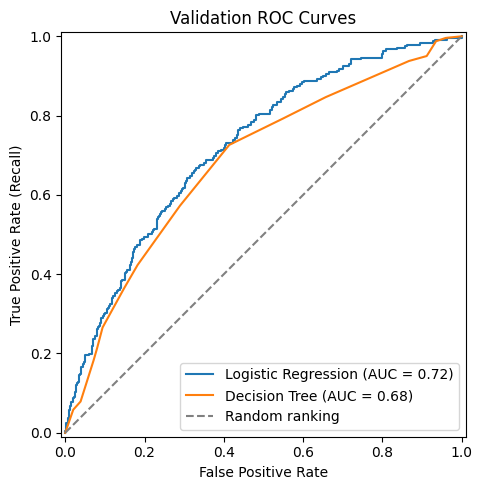

In [19]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

# Compare ROC curves on the validation set
fig, ax = plt.subplots(figsize=(7, 5))

for name, model in models.items():
    validation_scores = model.predict_proba(X_val)[:, 1]

    RocCurveDisplay.from_predictions(
        y_val,
        validation_scores,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.set_title("Validation ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

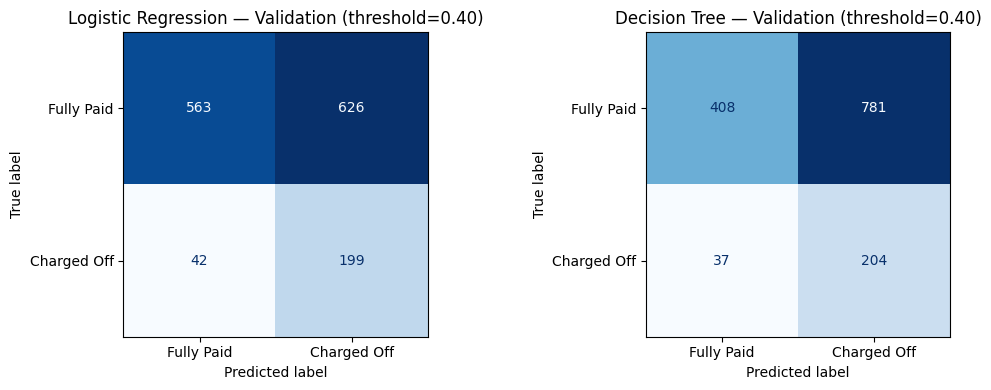

In [20]:
# Compare validation errors at the shared operating threshold
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(axes, models.items()):
    validation_scores = model.predict_proba(X_val)[:, 1]
    validation_predictions = (validation_scores >= THRESHOLD).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        validation_predictions,
        labels=[0, 1],
        display_labels=["Fully Paid", "Charged Off"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )

    ax.set_title(f"{name} — Validation (threshold={THRESHOLD:.2f})")

plt.tight_layout()
plt.show()

In [21]:
# Lock the model choice and threshold using validation results only.
validation_at_threshold = validation_comparison.loc[
    validation_comparison["Threshold"].eq(THRESHOLD)
].set_index("Model")
final_model_name = validation_at_threshold["ROC AUC"].idxmax()
final_model = models[final_model_name]
final_threshold = THRESHOLD
selected_validation = validation_at_threshold.loc[final_model_name]

display(Markdown(
    f"### 6.3 Model Recommendation\n\n"
    f"Selected **{final_model_name}** with **{selected_feature_sets[final_model_name]}** "
    f"by validation ROC AUC (**{selected_validation['ROC AUC']:.3f}**). "
    f"At threshold **{final_threshold:.2f}**, validation recall is "
    f"**{selected_validation['Recall']:.1%}**, precision **{selected_validation['Precision']:.1%}**, "
    f"and flagged rate **{selected_validation['Flagged Rate']:.1%}**. "
    "The table above shows the trade-off against 0.50. This operating point emphasizes "
    "default detection but has not been optimized for investment returns. "
    "The selected fitted model and threshold are now frozen for final testing."
))

### 6.3 Model Recommendation

Selected **Logistic Regression** with **Income ratios (11 features)** by validation ROC AUC (**0.722**). At threshold **0.40**, validation recall is **82.6%**, precision **24.1%**, and flagged rate **57.7%**. The table above shows the trade-off against 0.50. This operating point emphasizes default detection but has not been optimized for investment returns. The selected fitted model and threshold are now frozen for final testing.

### 6.4 Final Test Performance

Evaluate the model selected above on the held-out test set, keeping its fitted
parameters and `final_threshold` unchanged. Test results are for reporting;
do not use them to revise feature selection, the model, or the threshold.

This notebook's test set has already been evaluated in earlier versions.
The rerun verifies the corrections on the same split; a new untouched cohort
would be required for an independent assessment of the revised workflow.

,Threshold,Recall,Precision,F1,ROC AUC,Flagged Rate
Logistic Regression — Test,0.4,0.798,0.241,0.37,0.721,0.56


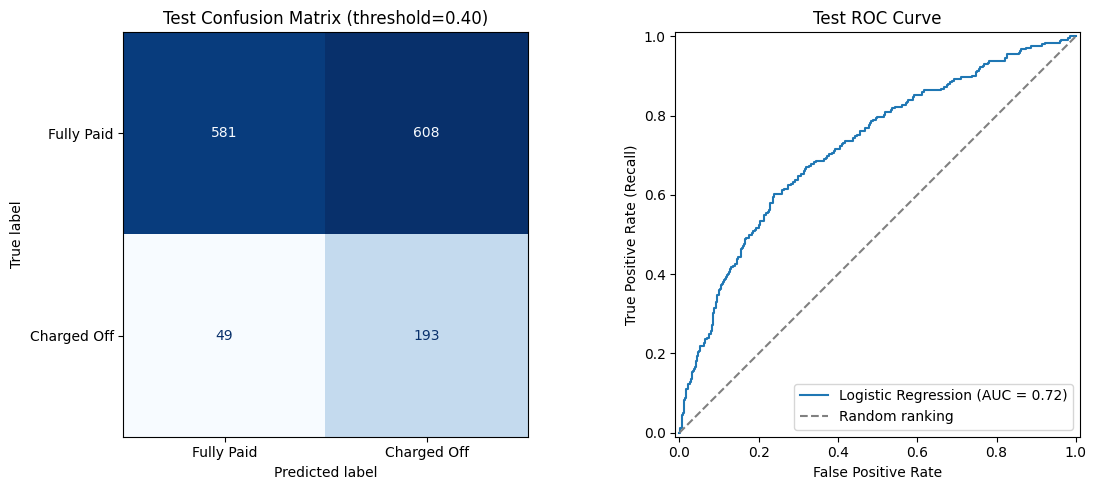

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Evaluate the choice frozen in Section 6.3; do not select anything here.

test_scores = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= final_threshold).astype(int)

# Display final test metrics
test_performance = pd.DataFrame([{
    "Threshold": final_threshold,
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, test_scores),
    "Flagged Rate": test_predictions.mean()
}], index=[f"{final_model_name} — Test"])

display(test_performance.round(3))

# Display the confusion matrix and ROC curve side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Fully Paid", "Charged Off"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0]
)
axes[0].set_title(f"Test Confusion Matrix (threshold={final_threshold:.2f})")

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=final_model_name,
    ax=axes[1]
)
axes[1].plot(
    [0, 1], [0, 1], "--", color="gray", label="Random ranking"
)
axes[1].set_title("Test ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [23]:
tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
m = test_performance.iloc[0]
display(Markdown(
    f"### Key Findings from Final Testing\n\n"
    f"**{final_model_name}**, threshold **{final_threshold:.2f}**: "
    f"ROC AUC **{m['ROC AUC']:.3f}**, recall **{m['Recall']:.1%}**, "
    f"precision **{m['Precision']:.1%}**, flagged rate **{m['Flagged Rate']:.1%}**. "
    f"Identified **{tp} of {tp + fn}** charged-off loans and missed **{fn}**. "
    f"Flagged **{tp + fp}** loans, including **{fp}** fully paid loans.\n\n"
    "The false positives represent forgone opportunities if flags are used for automatic exclusion. "
    "These scores support further review and are not calibrated default probabilities. "
    "Results describe this dataset and split; future-cohort performance is untested."
))

### Key Findings from Final Testing

**Logistic Regression**, threshold **0.40**: ROC AUC **0.721**, recall **79.8%**, precision **24.1%**, flagged rate **56.0%**. Identified **193 of 242** charged-off loans and missed **49**. Flagged **801** loans, including **608** fully paid loans.

The false positives represent forgone opportunities if flags are used for automatic exclusion. These scores support further review and are not calibrated default probabilities. Results describe this dataset and split; future-cohort performance is untested.

### 6.5 Model Interpretation

#### Logistic Regression Coefficients

Examine the fitted coefficients to understand the direction of each
feature's association with charge-off:

- **Positive coefficient:** Higher model-predicted odds of charge-off.
- **Negative coefficient:** Lower model-predicted odds of charge-off.

For numerical features, coefficients represent a one-standard-deviation
increase after preprocessing. For `annual_inc`, `revol_bal`, and (if retained) `revol_bal_to_income`, this
increase is measured on the log-transformed scale.

Categorical coefficients compare each category with its omitted reference
category. Their magnitudes are not directly comparable with standardized
numerical coefficients.

These coefficients describe associations learned by the model, not
causal effects. Because the model uses class weighting, its output scores
should not automatically be interpreted as calibrated default probabilities.

,Feature,Coefficient
10,home_ownership_RENT,0.528
4,int_rate,0.461
7,acc_open_past_24mths,0.209
5,revol_util,0.205
3,loan_amnt,0.176
2,log1p_revol_bal_to_income,0.167
9,home_ownership_OWN,0.130
12,verification_status_Verified,0.125
11,verification_status_Source Verified,0.019
6,total_acc,0.016


,Feature,Reference Category
0,home_ownership,MORTGAGE
1,verification_status,Not Verified


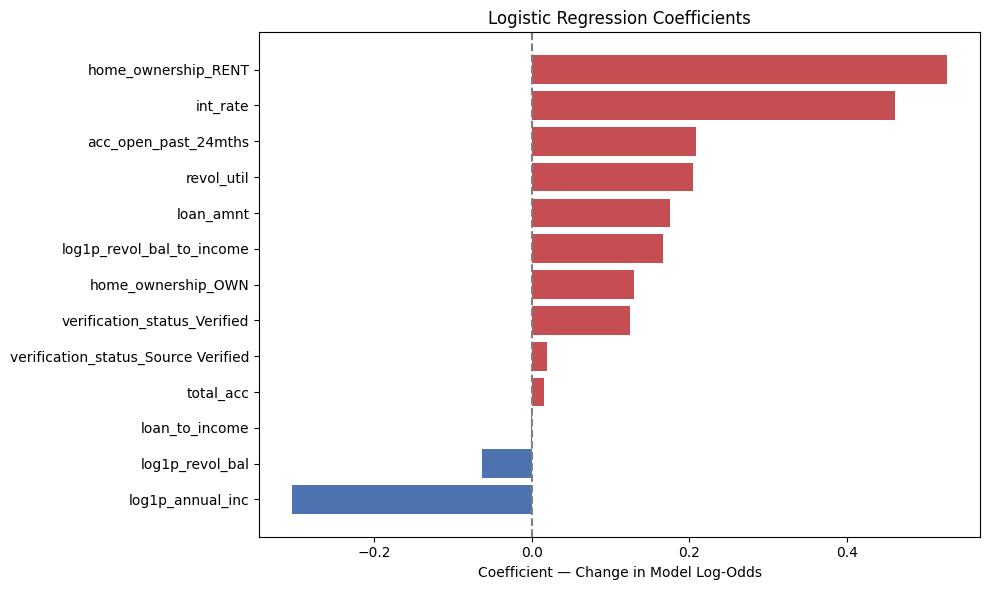

In [24]:
# Match each coefficient to its processed feature name
feature_names = (
    lr_model.named_steps["preprocessing"].get_feature_names_out()
)

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_model.named_steps["model"].coef_[0]
})

# Simplify labels while preserving the log-transformation information
coefficients["Feature"] = (
    coefficients["Feature"]
    .str.replace("log_numeric__", "log1p_", regex=False)
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

display(coefficients.sort_values("Coefficient", ascending=False).round(3))

# Identify the omitted reference categories
encoder = (
    lr_model.named_steps["preprocessing"]
    .named_transformers_["categorical"]
)

display(pd.DataFrame({
    "Feature": categorical_columns,
    "Reference Category": [values[index] for values, index in zip(encoder.categories_, encoder.drop_idx_)]
}))

# Plot the direction and magnitude of the coefficients
plot_data = coefficients.sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"],
    color=np.where(plot_data["Coefficient"] > 0, "#C44E52", "#4C72B0")
)
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Coefficient — Change in Model Log-Odds")
plt.title("Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

#### Key Findings — Logistic Regression

Higher interest rates, greater revolving credit utilization, more recently
opened accounts, and larger loan amounts are associated with higher
model-predicted charge-off risk, holding other predictors constant.
Higher log-transformed income is associated with lower predicted risk.

Renters have higher predicted odds of charge-off than mortgage borrowers.
Verified borrowers also have higher predicted odds than Not Verified
borrowers, although this association does not establish a causal effect.

Interest rate has the largest positive coefficient among standardized
numerical features. Categorical coefficients represent comparisons with
reference groups and should not be ranked directly against numerical
coefficients as a measure of overall feature importance.

These findings explain the fitted model's behavior; they do not establish
causality, statistical significance, or calibrated default probabilities.

#### Decision Tree Interpretation

The Decision Tree predicts loan outcomes through a sequence of feature-based
rules. Each split divides loans into groups, and each terminal node assigns
a predicted class.

Display the first three levels for readability. The fitted tree retains
its original maximum depth of four; this visualization does not change it.

Numerical thresholds use the original feature units because the tree's
inputs were not scaled. Categorical indicators use 0 for absence and 1
for membership in a category.

Because the model uses balanced class weights, the displayed class
proportions are weighted and should not be interpreted as observed
charge-off rates.

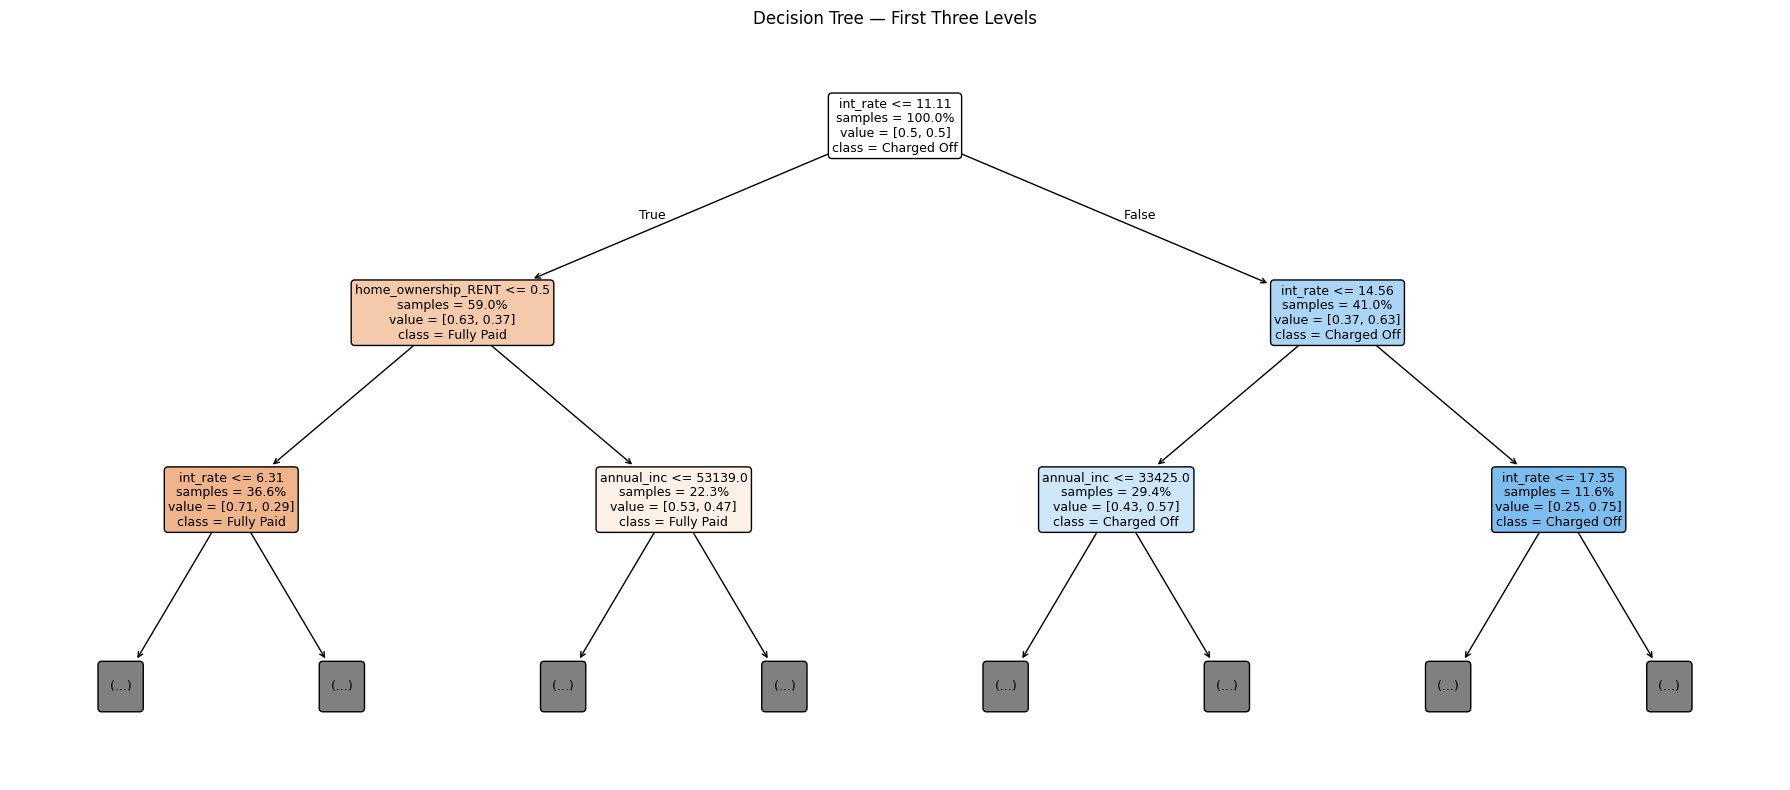

In [25]:
from sklearn.tree import plot_tree

# Retrieve the fitted tree and its processed feature names
fitted_tree = tree_model.named_steps["model"]
tree_feature_names = (
    tree_model.named_steps["preprocessing"].get_feature_names_out()
)

# Remove preprocessing prefixes for readability
tree_feature_names = [
    name.split("__", 1)[-1] for name in tree_feature_names
]

# Display the first three levels without changing the fitted model
plt.figure(figsize=(18, 8))

plot_tree(
    fitted_tree,
    feature_names=tree_feature_names,
    class_names=["Fully Paid", "Charged Off"],
    max_depth=2,
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    precision=2,
    fontsize=9
)

plt.title("Decision Tree — First Three Levels")
plt.tight_layout()
plt.show()

#### Reading the Decision Tree

The plot above is generated from the selected tree variant on this run.
Read its feature names and numerical thresholds directly from the nodes;
adding ratio features can change the learned splits. The first split is the
root decision and the remaining branches apply conditional rules.

Class proportions use training class weights, not observed default rates.
The first three levels are shown; predictions also depend on deeper branches.
The final model recommendation is based on validation performance in Section 6.3.

## 7. AWS Deployment

### 7.1 Architecture and Required Resources

Deploy the selected pipeline as a batch-scoring
workflow. Investment analysts upload loan records and receive risk
scores for review.

| AWS Resource | Purpose |
|---|---|
| Amazon S3 | Store the model artifact, incoming loan records, and prediction outputs. |
| Amazon SageMaker AI Batch Transform | Load the saved pipeline and score batches of loans. |
| AWS IAM | Give SageMaker permission to access the required storage, container image, and logs. |
| Amazon CloudWatch | Collect execution logs and support operational monitoring. |

The deployed artifact must include feature engineering, preprocessing, and the selected classifier
together so new loans receive the same transformations used during training.

### 7.2 Implementation Steps

1. **Save the selected pipeline**
   Export `final_model` using `joblib` and save `final_threshold` alongside it.
   Record the nine raw input features, selected feature variant, target encoding,
   model version, and Python dependency versions. If income ratios are retained,
   move `add_income_ratios` into an importable Python module and use that module
   when fitting and loading the artifact; a notebook-local function alone is not
   portable to a fresh inference process. The pipeline calculates both ratios.

2. **Prepare the inference code**
   Create an inference script that loads the pipeline, reads incoming
   records into a DataFrame, validates the required columns and data types,
   and returns a risk score and high-risk flag for each loan.

   Preserve loan IDs for matching predictions to records, but exclude IDs
   from model inputs. Do not fit preprocessing again during inference.

3. **Configure AWS storage and permissions**
   Create a private S3 bucket with separate locations for model artifacts,
   input files, and outputs. Create a SageMaker execution role with the
   permissions required for these resources.

4. **Create the SageMaker model**
   Package and upload the saved pipeline. Configure a compatible
   scikit-learn inference container with the inference script and matching
   dependencies, then create a SageMaker model resource.

5. **Verify a small batch**
   Run a small batch through AWS and compare its scores with local
   predictions for the same records. Check missing values, category
   handling, record IDs, and output completeness.

6. **Run batch scoring**
   Upload new loan records to S3 and start a Batch Transform job, specifying
   the model, input format, compute resources, and output location.

7. **Deliver results**
   Produce an output containing loan ID, risk score, high-risk flag, and
   model version. Analysts use the results to support investment review.

   Scores from the class-weighted model should not be presented as
   calibrated default probabilities without further assessment.

### 7.3 Monitoring

- **Operational checks:** Monitor job failures, processing duration, and
  missing or incomplete prediction outputs.
- **Data checks:** Track missing values, unexpected categories, feature
  distributions, and changes in risk scores and the flagged rate.
- **Performance checks:** Once repayment outcomes become available,
  evaluate recall, precision, and ROC AUC on appropriately matured cohorts.
  Do not treat loans still being repaid as Fully Paid.
- **Model maintenance:** Investigate deterioration before retraining.
  Validate replacement models on newer data and retain previous model
  versions for rollback.

This is a proposed deployment workflow; AWS deployment has not been
performed as part of this analysis.

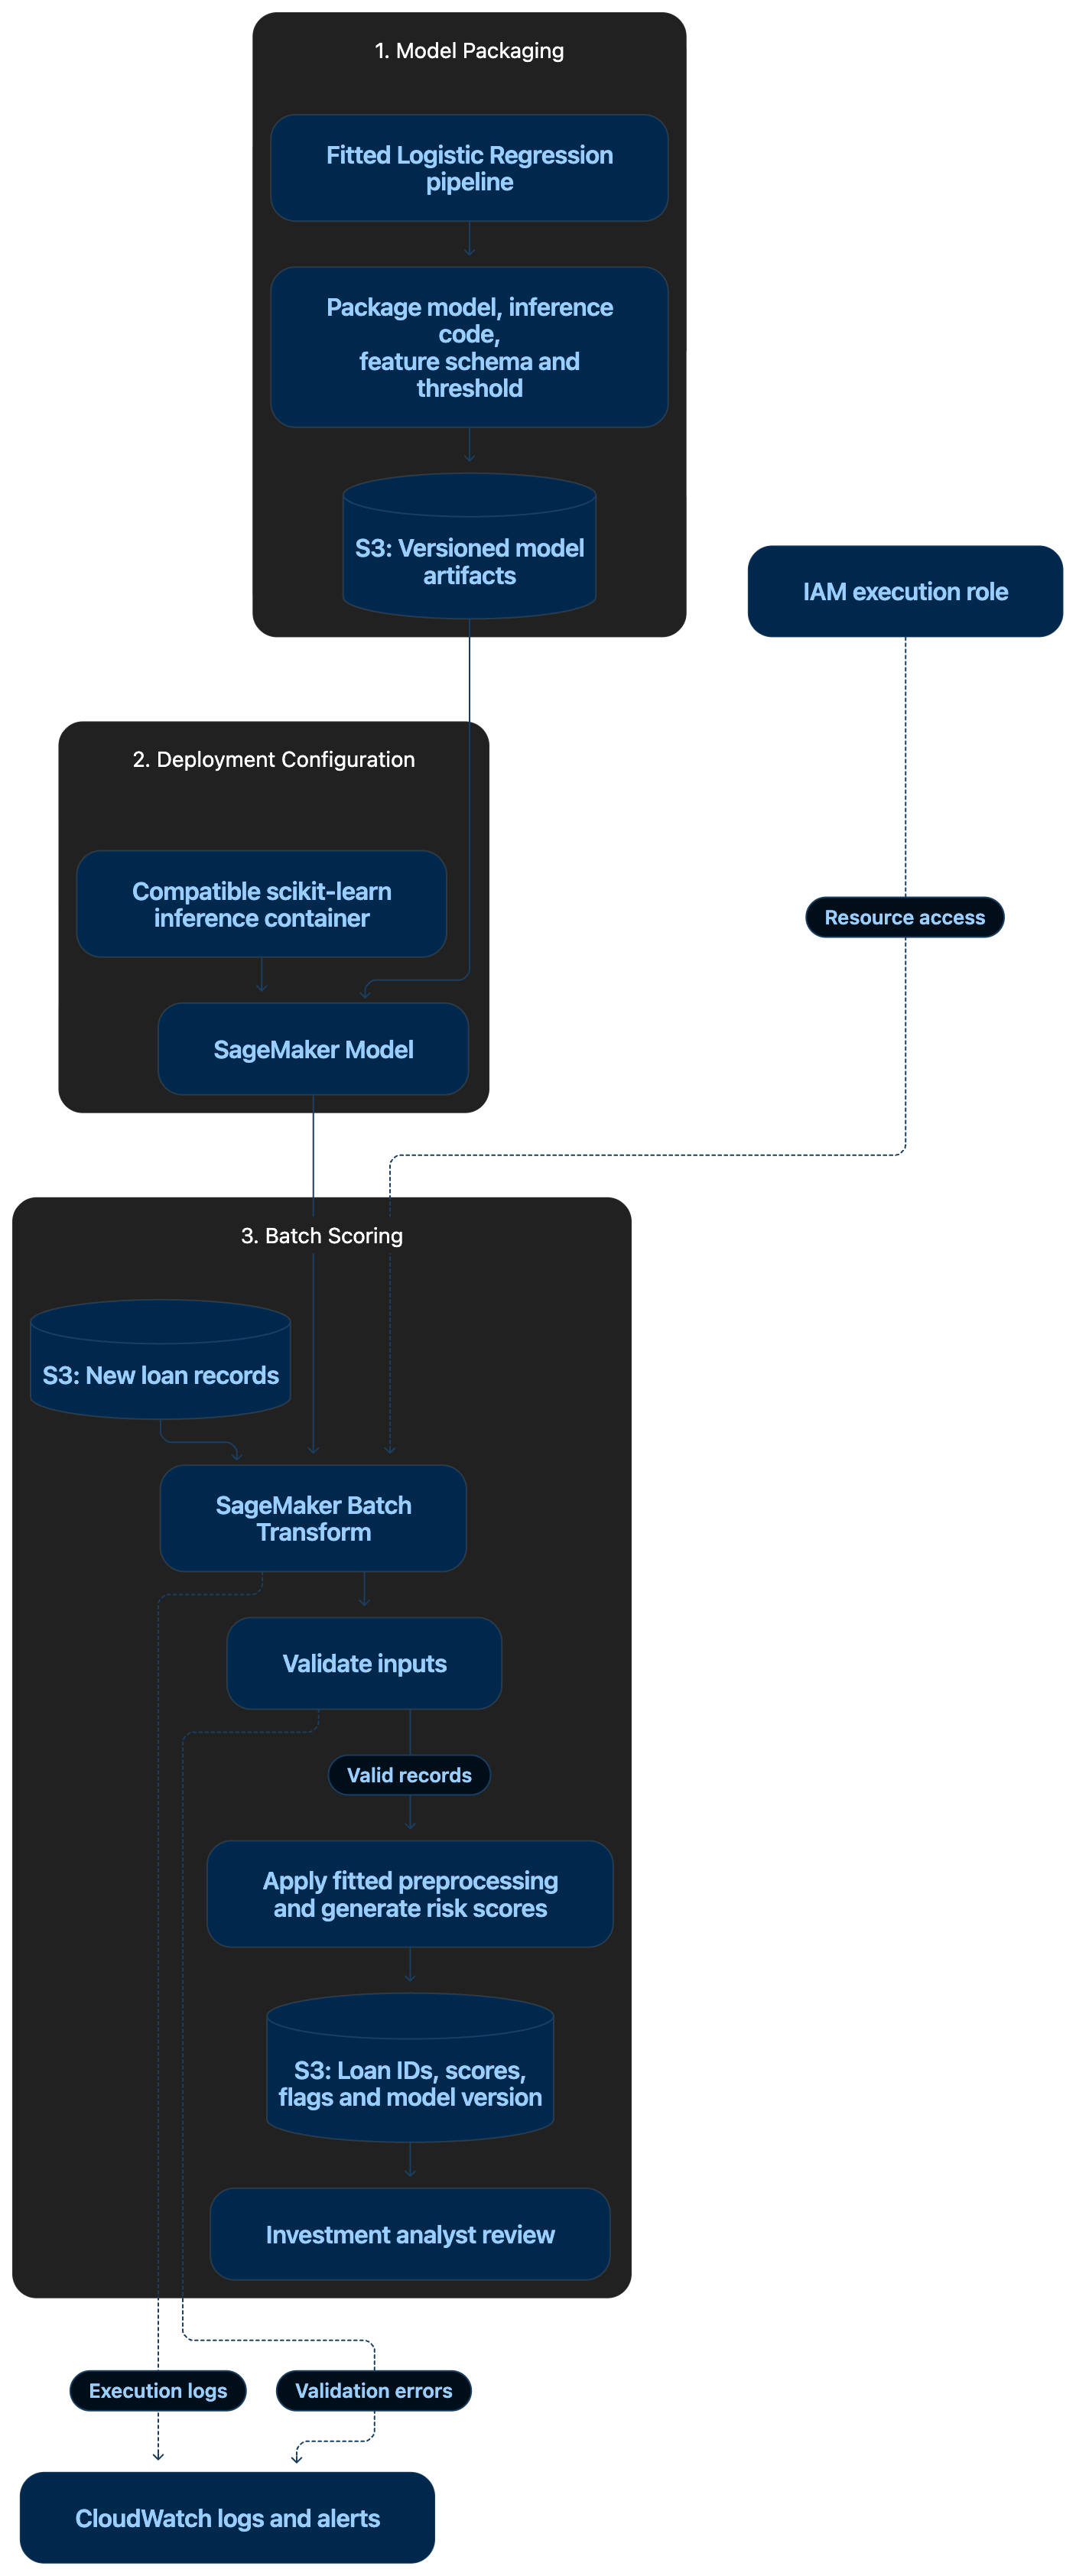